# Day 03 — Embeddings
**LLM Inference Engineering · 28-day series** · Prerequisite: Day 02

**Goal:** turn token IDs into the vectors the transformer actually works with, using GPT-2's real embedding tables.
Token IDs carry no meaning (ID 4821 is not "closer" to 4822 than to 9000). The embedding layer fixes that with a **lookup table**.
**Time:** about 25 minutes.

In [9]:
import os, json, struct, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

MODEL_DIR = "gpt2_weights"
BASE = "https://huggingface.co/openai-community/gpt2/resolve/main"
os.makedirs(MODEL_DIR, exist_ok=True)
for f in ["config.json", "vocab.json", "merges.txt", "model.safetensors"]:   # model.safetensors is ~550 MB, skipped if present
    p = os.path.join(MODEL_DIR, f)
    if not os.path.exists(p):
        print("downloading", f); urllib.request.urlretrieve(f"{BASE}/{f}", p)

def read_header(path):                                   # same parser as Day 02
    with open(path, "rb") as fh:
        n = struct.unpack("<Q", fh.read(8))[0]; h = json.loads(fh.read(n))
    h.pop("__metadata__", None); return h, 8 + n
def load_tensor(path, h, start, name):
    i = h[name]; cnt = int(np.prod(i["shape"]))
    return np.fromfile(path, dtype=np.float32, count=cnt, offset=start + i["data_offsets"][0]).reshape(i["shape"])

W = os.path.join(MODEL_DIR, "model.safetensors")
header, data_start = read_header(W)
wte = load_tensor(W, header, data_start, "wte.weight")    # token embeddings
wpe = load_tensor(W, header, data_start, "wpe.weight")    # position embeddings
tok = AutoTokenizer.from_pretrained(MODEL_DIR)
print("wte (token)    :", wte.shape, f"{wte.nbytes/1e6:.0f} MB")
print("wpe (position) :", wpe.shape, f"{wpe.nbytes/1e6:.1f} MB")

wte (token)    : (50257, 768) 154 MB
wpe (position) : (1024, 768) 3.1 MB


## 1. An embedding is a table lookup
Row *i* of `wte` is the vector for token *i*. Looking it up is the same as multiplying a one-hot vector by the table, but without doing any math.

In [10]:
text = "The cat sat on the mat"
ids = tok.encode(text)
E = wte[ids]                                   # lookup: [n_tokens, hidden]
print("token ids      :", ids)
print("embedding shape:", E.shape, " -> one", E.shape[1], "-dim vector per token")
print("first token, first 6 dims:", np.round(E[0, :6], 3))

onehot = np.zeros((len(ids), wte.shape[0]), dtype=np.float32)
onehot[np.arange(len(ids)), ids] = 1.0
print("lookup == one-hot @ table:", np.allclose(onehot @ wte, E, atol=1e-5))

token ids      : [464, 3797, 3332, 319, 262, 2603]
embedding shape: (6, 768)  -> one 768 -dim vector per token
first token, first 6 dims: [-0.069 -0.02   0.064 -0.062 -0.114 -0.062]
lookup == one-hot @ table: True


## 2. Position: the second table
Attention (Day 04) has no built-in sense of order. GPT-2 therefore **adds** a learned position vector to every token vector:

`input to block 0 = wte[token_id] + wpe[position]`

In [11]:
pos = np.arange(len(ids))
x0 = wte[ids] + wpe[pos]
print("input to the first transformer block:", x0.shape)

# Without positions, shuffling the words gives the SAME set of vectors:
shuffled = tok.encode("mat the on sat cat The")
same_bag = sorted(map(tuple, np.round(wte[ids], 4))) == sorted(map(tuple, np.round(wte[shuffled], 4)))
print("same multiset of token vectors without position info:", same_bag)
print("with positions the inputs differ:", not np.allclose(x0, wte[shuffled] + wpe[np.arange(len(shuffled))]))

input to the first transformer block: (6, 768)
same multiset of token vectors without position info: False
with positions the inputs differ: True


## 3. Is there meaning in the geometry?
Closeness is measured with **cosine similarity**. Let's find the nearest tokens to a few words. (Words need a leading space to be a single GPT-2 token.)

In [12]:
def unit(v): return v / (np.linalg.norm(v, axis=-1, keepdims=True) + 1e-9)
wte_n = unit(wte)

def vec(word):
    ids_ = tok.encode(word)
    return (ids_[0], wte_n[ids_[0]]) if len(ids_) == 1 else (None, None)

def neighbors(word, k=8):
    i, v = vec(word)
    if i is None: print(f"{word!r}: not a single token, skipped"); return
    sims = wte_n @ v
    top = np.argsort(-sims)[1:k + 1]
    print(f"{word!r:>10s} -> " + ", ".join(repr(tok.decode([t])) for t in top))

for w in [" cat", " king", " Paris", " python", " January", " fast"]:
    neighbors(w)

    ' cat' -> ' Cat', ' cats', 'Cat', 'cat', ' dog', ' Cats', ' CAT', ' kitten'
   ' king' -> ' kings', ' King', ' queen', 'King', ' prince', ' monarch', ' emperor', ' ruler'
  ' Paris' -> 'Paris', ' France', ' French', ' London', 'France', ' Copenhagen', ' Brussels', 'French'
 ' python' -> ' Python', 'python', 'Python', ' snake', ' ruby', ' javascript', ' php', ' perl'
' January' -> ' February', ' December', ' November', 'January', ' October', ' July', ' April', ' March'
   ' fast' -> ' Fast', 'fast', 'Fast', ' faster', ' quick', ' quickly', ' fastest', ' rapidly'


In [13]:
# The famous analogy: king - man + woman ~ queen  (noisy in INPUT embeddings, so treat it as a demo)
parts = [vec(w) for w in [" king", " man", " woman"]]
if all(p[0] is not None for p in parts):
    target = unit(parts[0][1] - parts[1][1] + parts[2][1])
    sims = wte_n @ target
    for t in [p[0] for p in parts]: sims[t] = -1           # exclude the inputs themselves
    print("king - man + woman ->", [tok.decode([t]) for t in np.argsort(-sims)[:5]])

king - man + woman -> [' queen', ' princess', ' Queen', ' kings', 'Queen']


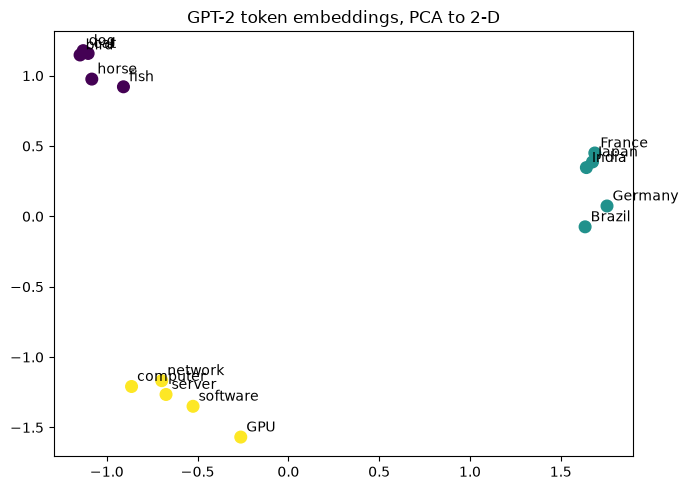

In [14]:
# Project a handful of words to 2-D with PCA (SVD) to see clusters
groups = {"animals": [" cat", " dog", " horse", " bird", " fish"],
          "countries": [" France", " Germany", " India", " Japan", " Brazil"],
          "tech": [" computer", " server", " network", " software", " GPU"]}
pts, labels, colors = [], [], []
for ci, (g, ws) in enumerate(groups.items()):
    for w in ws:
        i, v = vec(w)
        if i is not None: pts.append(wte[i]); labels.append(w.strip()); colors.append(ci)
if len(pts) >= 4:
    P = np.array(pts); P = P - P.mean(0)
    _, _, Vt = np.linalg.svd(P, full_matrices=False); xy = P @ Vt[:2].T
    plt.figure(figsize=(7, 5)); plt.scatter(xy[:, 0], xy[:, 1], c=colors, cmap="viridis", s=70)
    for (x, y), l in zip(xy, labels): plt.annotate(l, (x, y), xytext=(4, 4), textcoords="offset points")
    plt.title("GPT-2 token embeddings, PCA to 2-D"); plt.tight_layout(); plt.show()

## 4. Beyond a learned table: RoPE
Llama-style models do not store `wpe`. **Rotary position embeddings** rotate pairs of dimensions of the query and key vectors by an angle proportional to position. The key property: the attention score depends only on the **distance** between two tokens, and there is no hard length limit.

In [15]:
def rope(x, pos, base=10000.0):
    # rotate consecutive pairs (x0,x1),(x2,x3),... of vector x by angle pos * theta_i
    d = x.shape[-1]; theta = base ** (-np.arange(0, d, 2) / d)
    ang = pos * theta; c, s = np.cos(ang), np.sin(ang)
    out = np.empty_like(x); out[0::2] = x[0::2] * c - x[1::2] * s; out[1::2] = x[0::2] * s + x[1::2] * c
    return out

rng = np.random.default_rng(0); q, k = rng.normal(size=64), rng.normal(size=64)
print("score(q@m, k@n) for pairs with the same distance m-n = 3:")
for m, n_ in [(3, 0), (10, 7), (500, 497), (4000, 3997)]:
    print(f"  m={m:>4d} n={n_:>4d}  ->  {rope(q, m) @ rope(k, n_):.6f}")
assert np.allclose(rope(q, 3) @ rope(k, 0), rope(q, 4000) @ rope(k, 3997))
print("\nsame distance -> same score: position is encoded as RELATIVE offset")

score(q@m, k@n) for pairs with the same distance m-n = 3:
  m=   3 n=   0  ->  -8.446152
  m=  10 n=   7  ->  -8.446152
  m= 500 n= 497  ->  -8.446152
  m=4000 n=3997  ->  -8.446152

same distance -> same score: position is encoded as RELATIVE offset


## 5. Embedding tables and memory
`table bytes = vocab x hidden x bytes per value`. Bigger vocabularies cost memory but shorten sequences (Day 02).

In [16]:
models = {"GPT-2": (50257, 768), "Llama 2 7B": (32000, 4096), "Llama 3 8B": (128256, 4096), "Llama 3 70B": (128256, 8192)}
print(f"{'model':<14s}{'vocab':>9s}{'hidden':>8s}{'FP16 table':>12s}")
for m, (v, h) in models.items():
    print(f"{m:<14s}{v:>9,}{h:>8d}{v * h * 2 / 1e9:>10.2f} GB")

model             vocab  hidden  FP16 table
GPT-2            50,257     768      0.08 GB
Llama 2 7B       32,000    4096      0.26 GB
Llama 3 8B      128,256    4096      1.05 GB
Llama 3 70B     128,256    8192      2.10 GB


## Recap
- Embedding = **row lookup** in a `[vocab, hidden]` table. It is the first and cheapest layer.
- GPT-2 adds a learned position vector: `wte[token] + wpe[position]`. Llama-style models use RoPE instead.
- Geometry carries meaning: nearby vectors are related tokens.
- The table costs `vocab x hidden x bytes`, about 1 GB at FP16 for Llama 3 8B.

### Try it yourself
1. Find the nearest neighbours of ` Kubernetes`. Why might it be skipped?
2. Change the RoPE `base` to 500000. What happens to the scores at large distances?

**Next — Day 04:** attention: how tokens look at each other.